# Data like India's: an IRIS C-band radar on a mountain (Tablazo, Colombia), 20 Aug 2023

**Why this radar.** IMD's radars write Vaisala/Sigmet IRIS files, one sweep per file, and several of them sit on
Himalayan peaks. Colombia's IDEAM publishes exactly that kind of data openly: Tablazo is a C-band dual-pol IRIS
radar at 3,544 m in the Andes above Bogota, with every sweep in its own file. IDEAM also publishes 10-minute
rain gauges. Nothing like MRMS exists here; the gauges are the reference.

**What is new for the chain.** Assembling a volume from one-sweep files (`ideam_aws_files`, `open_volume` with a
list), the band from the IRIS header wavelength (5.33 cm, C band), terrain blockage from a radar far above much of
its surroundings, and a 0 C level only ~1.3 km above the antenna.

**Case.** 20 Aug 2023, 00-12 UTC: hours of widespread rain around the radar in the gauges.

In [1]:
# Colab: uncomment to install
!pip install -q pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-merging"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.core import diagnose, ideam_aws_files, open_volume
from radarwow.merging import leave_one_out, radar_at
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_ideam

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "Tablazo", "2023-08-20 00:00", "2023-08-20 12:00"

## 1. One volume from one-sweep files

In [3]:
c0, paths = ideam_aws_files(SITE, START, pd.Timestamp(START) + pd.Timedelta(minutes=5), cache_dir=f"{CACHE}/ideam")[0]
dt0 = open_volume(paths)
lat0, lon0, alt = (float(dt0[k].values) for k in ("latitude", "longitude", "altitude"))
sw = sorted((k for k in dt0.children if k.startswith("sweep")), key=lambda s: int(s.split("_")[1]))
display(Markdown(f"{len(paths)} files in the {c0:%H:%M} cycle -> one volume of {len(sw)} sweeps; band "
                 f"{dt0.attrs['radarwow_band']} (wavelength {dt0.attrs['wavelength_m'] * 100:.2f} cm); radar at {lat0:.3f} N, "
                 f"{lon0:.3f} E, {alt:.0f} m.\n\n" + "\n".join(
                     f"- {k}: {float(np.nanmedian(dt0[k].to_dataset()['elevation'])):.1f} deg, "
                     + ("dual-pol" if "PHIDP" in dt0[k].to_dataset() else "reflectivity only") for k in sw)))
display(diagnose(dt0))

10 files in the 00:00 cycle -> one volume of 18 sweeps; band C (wavelength 5.33 cm); radar at 5.012 N, -74.204 E, 3544 m.

- sweep_0: 0.0 deg, dual-pol
- sweep_1: 0.0 deg, reflectivity only
- sweep_2: 0.5 deg, reflectivity only
- sweep_3: 0.5 deg, dual-pol
- sweep_4: 1.0 deg, reflectivity only
- sweep_5: 1.0 deg, dual-pol
- sweep_6: 2.0 deg, reflectivity only
- sweep_7: 2.0 deg, dual-pol
- sweep_8: 4.5 deg, reflectivity only
- sweep_9: 4.5 deg, dual-pol
- sweep_10: 7.0 deg, reflectivity only
- sweep_11: 7.0 deg, dual-pol
- sweep_12: 10.0 deg, reflectivity only
- sweep_13: 10.0 deg, dual-pol
- sweep_14: 15.0 deg, reflectivity only
- sweep_15: 15.0 deg, dual-pol
- sweep_16: 25.0 deg, reflectivity only
- sweep_17: 25.0 deg, dual-pol

**Tablazo, Radar** (band C, sweep_0)

| severity | topic | finding | remedy |
|---|---|---|---|
| fix | geometry | 1 azimuth gaps and 0 duplicate rays (resolution 1.00 deg) | regrid azimuths before texture/KDP filters (core.geometry) |
| fix | noise | noise gates are stored, not censored (floor ~-81 dBZ at 1 km, rising 20 log r); 69% of gates are signal | qc: signal mask (SNR or noise-floor + 3 dB) before any other step |
| fix | PHIDP | system PHIDP offset ~68 deg (median of first rain gates) | kdp: subtract offset / use offset-free derivative (Vulpiani 2012) |
| fix | ZDR | median ZDR at 20-28 dBZ, rhoHV > 0.98 = -2.62 dB; expected ~ +0.2-0.3 dB *if this is rain* (snow plates/dendrites can be higher) | calibration: ZDR offset (Ryzhkov et al. 2005); confirm with vertical scans or Sun |
| info | clutter | both total (DBTH) and filtered (DBZH) reflectivity present | DBTH - DBZH = clutter power removed by the signal processor |

## 2. Which clock do the gauges use?
The open dataset does not say whether its times are UTC or Colombian local time (UTC-5). The radar decides: the
offset that makes radar and gauge hours agree best is the right one.

In [4]:
rad = hourly_totals(SITE, START, END, n_tilts=3, blockage=True, source="ideam")
x, y = rad["x"].values, rad["y"].values
best = None
for off in [0, 5]:
    g = fetch_ideam(lat0, lon0, 145, START, END, f"{CACHE}/gauges", utc_offset_h=off)
    g["gx"] = (g.lon - lon0) * 111.2 * np.cos(np.deg2rad(lat0))
    g["gy"] = (g.lat - lat0) * 111.2
    g["radar"] = np.nan
    for t, idx in g.groupby("time").groups.items():
        g.loc[idx, "radar"] = radar_at(rad["RAIN"].sel(time=t).values, x, y, g.loc[idx, "gx"].values, g.loc[idx, "gy"].values)
    m = np.isfinite(g.radar)
    r = np.corrcoef(g.radar[m], g.gauge_mm[m])[0, 1]
    display(Markdown(f"gauge time + {off} h = UTC: correlation with radar {r:.2f} over {m.sum()} gauge-hours"))
    if best is None or r > best[0]:
        best = (r, off, g)
r_best, OFFSET, g = best
display(Markdown(f"**Using + {OFFSET} h.**"))

gauge time + 0 h = UTC: correlation with radar 0.00 over 196 gauge-hours

gauge time + 5 h = UTC: correlation with radar 0.53 over 195 gauge-hours

**Using + 5 h.**

## 3. Radar against the gauges

In [5]:
g = basic_qc(g, radar_col="radar")
ok = g[g.qc == "ok"]


def stats(e, r):
    m = np.isfinite(e) & np.isfinite(r)
    return dict(n=int(m.sum()), bias=e[m].sum() / r[m].sum(), MAE=np.mean(np.abs(e[m] - r[m])), corr=np.corrcoef(e[m], r[m])[0, 1])


rows = [dict(estimate="radar-wow chain", **stats(ok.radar.values, ok.gauge_mm.values))]
loo, obs = {m: [] for m in ["MFB", "conditional merging", "KED"]}, []
for t, gt in ok.groupby("time"):
    f = rad["RAIN"].sel(time=t).values
    for m in loo:
        loo[m] += list(leave_one_out(m, f, x, y, gt.gx.values, gt.gy.values, gt.gauge_mm.values))
    obs += list(gt.gauge_mm.values)
rows += [dict(estimate=f"+ gauges: {m} (leave-one-out)", **stats(np.array(v), np.array(obs))) for m, v in loo.items()]
display(Markdown(f"{g.station.nunique()} gauges; QC: " + ", ".join(f"{a}: {b}" for a, b in g.qc.value_counts().items())
                 + "\n\n" + pd.DataFrame(rows).round(2).to_markdown(index=False)))

19 gauges; QC: ok: 191, no radar value: 22, gauge dry under radar rain: 4

| estimate                                      |   n |   bias |   MAE |   corr |
|:----------------------------------------------|----:|-------:|------:|-------:|
| radar-wow chain                               | 191 |   0.61 |  0.72 |   0.58 |
| + gauges: MFB (leave-one-out)                 | 191 |   1.26 |  1.17 |   0.35 |
| + gauges: conditional merging (leave-one-out) | 191 |   1.13 |  1.2  |   0.3  |
| + gauges: KED (leave-one-out)                 | 191 |   1.43 |  1.36 |   0.29 |

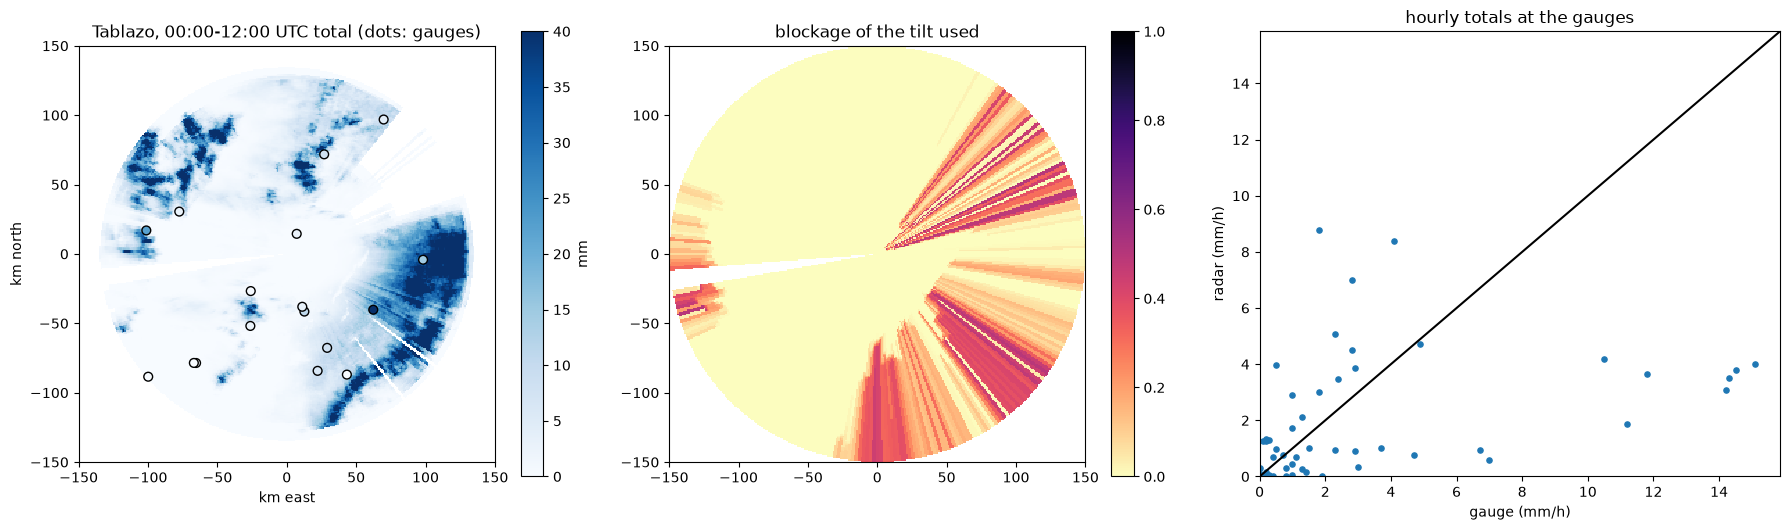

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
tot = rad["RAIN"].sum("time", min_count=1).values
p = axes[0].pcolormesh(x, y, np.ma.masked_invalid(tot), cmap="Blues", vmin=0, vmax=40, shading="auto")
gs = ok.groupby("station").agg(gauge=("gauge_mm", "sum"), gx=("gx", "first"), gy=("gy", "first"))
axes[0].scatter(gs.gx, gs.gy, c=gs.gauge, cmap="Blues", vmin=0, vmax=40, s=40, edgecolors="k")
axes[0].set(title=f"Tablazo, {START[11:16]}-{END[11:16]} UTC total (dots: gauges)", aspect=1, xlabel="km east", ylabel="km north")
fig.colorbar(p, ax=axes[0], label="mm")
b = axes[1].pcolormesh(x, y, np.ma.masked_invalid(rad["BLOCKAGE"].values), cmap="magma_r", vmin=0, vmax=1, shading="auto")
axes[1].set(title="blockage of the tilt used", aspect=1)
fig.colorbar(b, ax=axes[1])
axes[2].scatter(ok.gauge_mm, ok.radar, s=14)
lim = max(ok.gauge_mm.max(), ok.radar.max()) * 1.05
axes[2].plot([0, lim], [0, lim], "k")
axes[2].set(xlabel="gauge (mm/h)", ylabel="radar (mm/h)", title="hourly totals at the gauges", xlim=(0, lim), ylim=(0, lim))
fig.tight_layout()
fig.savefig(f"{FIG}/16_tablazo.png", dpi=100)
plt.show()

## Takeaways
- **The IRIS path works on India-style data.** Ten files per 5-minute cycle (nine one-sweep dual-pol files and a
  reflectivity-only volume) become one 18-sweep volume; the chain picks the dual-pol sweep at each of the nine
  elevations; the band comes from the IRIS header (5.33 cm, C band).
- **The health check finds a real instrument problem:** median ZDR -2.6 dB in light rain, a calibration offset that
  would need fixing before ZDR is used (here it only enters the small differential-attenuation correction).
- **The gauges are in local time** (UTC-5): radar-gauge correlation 0.50 with the shift, -0.04 without. The open
  dataset does not say so.
- **A mountain-top radar needs a free-atmosphere 0 C level.** The first run took the 0 C prior from the 2 m
  temperature of the radar's grid cell (3,419 m, 4-8 C at night): 0 C only 0.6-1.2 km above the antenna, and with no
  melting layer detected the rain mask left 2-26 % of the disk. Pressure-level temperatures put 0 C at ~5.2 km
  (1.6 km above the antenna, typical for the tropics); valid area 48-58 %, gauges covered 189 of 217 gauge-hours.
  Outside the US the pipeline now uses `pressure_level_freezing_level`.
- **Spurious phase, caught by a consistency test.** The first estimate was 1.9-2.2 times the gauges. The
  attenuation-based rate was the cause: on this radar PHIDP rises 40-110 deg through rain of only 25-35 dBZ, where
  rain that weak can produce a few degrees, and R(A) turned that into 11-16 mm/h where Z suggested ~2. Excluding
  clutter-filtered gates from the phase barely helped (2.16 -> 2.09). radarwow-attenuation now compares each ray's
  PHIDP rise with the rise its Z could produce (Marshall-Palmer, then the band's R(KDP) relation inverted): the
  median ratio is 1.2-1.6 on KTLX, KDAX and fianj, 18 on Tablazo. Rays above 10x get no attenuation correction and no
  R(A) (heavy convective rain, where Marshall-Palmer underestimates, reaches ~5x). On Tablazo 83 % of rays fail; the
  bias went from 1.88 to 0.61 and the error fell 43 % (MAE 1.27 -> 0.72 mm). The other radars changed by 0-3 %
  (one FMI radar hour by 43 %, improving the Finnish mosaic).
- **Still underestimating, and gauges do not help here:** 0.61 of the gauges, correlation 0.58. The beam passes
  ~1 km above valley gauges and misses shallow rain, and partial blockage below 50 % is only corrected with a NEXRAD
  rule. Merging with 19 valley gauges makes it worse (leave-one-out), unlike every other case.
- **Lesson for IMD's Himalayan radars:** the format and volume assembly are solved; the 0 C level must come from the
  free atmosphere; dual-pol phase must be checked against reflectivity before R(A) is trusted; low-level rain below
  the beam and dense gauges are the next problems.